# ECGNextFormer — Rare-Age ("Rare-Shot") Research: End-to-End Notebook

**What this project does.** ECGNextFormer estimates a patient's **age from a 12-lead ECG** (age is the paper's proxy for cardiovascular well-being). "Rare-shot" means **rare ages** in PTB-XL (very young and very old patients have few ECGs). This notebook is **not** a heart-disease classifier; if you want disease prediction (e.g. PTB-XL superclasses NORM/MI/STTC/CD/HYP with rare-class handling), that is a different task and would need a different head/loss.

**Pipeline:** find/extract PTB-XL from your ZIP → audit metadata → validate waveforms → write model + training code → smoke tests → run baseline and rare-age methods → pooled out-of-fold comparison with confidence intervals.

**Methods compared**
| run | loss | sampler | checkpoint selection |
|---|---|---|---|
| `baseline_mse` | MSE | uniform | validation MSE (paper protocol) |
| `mse_balsel` | MSE | uniform | balanced validation MAE |
| `tamse_balsel` | Tail-aware weighted MSE (your proposed placeholder) | uniform | balanced validation MAE |
| `gai_balsel` | Balanced MSE (Ren et al. 2022, GAI) | uniform | balanced validation MAE |
| `sampler_aug` | MSE | balanced resampling + light ECG augmentation | balanced validation MAE |

**Honesty notes**
- `ecgnextformer.py` is a reconstruction from the paper, not official author code. `tamse` is your proposed method, not from the paper.
- Synthetic data only checks that code runs. Never report synthetic numbers.
- Few-shot test sets are tiny (~144 ECGs over all 10 folds). Compare methods on **pooled** out-of-fold predictions with bootstrap CIs, not on per-fold numbers.
- Original ZIP/dataset files are never modified.

## 0. Project configuration

In [ ]:
from pathlib import Path
import os, sys, json, zipfile, subprocess, time, random
import numpy as np
import pandas as pd

PROJECT_DIR = Path(r"C:\Users\Tankala Bhaskar teja\DS_FINAL_RESEARCH")
if not PROJECT_DIR.exists():
    raise FileNotFoundError(f"Project folder not found: {PROJECT_DIR}\nEdit PROJECT_DIR in this cell.")

DATASET_ZIP = None          # optionally the full path of the PTB-XL ZIP
EXTRACT_DIR = PROJECT_DIR / "PTBXL_EXTRACTED"
REPORT_DIR  = PROJECT_DIR / "dataset_reports"
CODE_DIR    = PROJECT_DIR / "code"
CACHE_DIR   = PROJECT_DIR / "cache"
RUNS_DIR    = PROJECT_DIR / "runs"
for d in [EXTRACT_DIR, REPORT_DIR, CODE_DIR, CACHE_DIR, RUNS_DIR]:
    d.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT_DIR)       # so the %%writefile cells below use paths relative to the project

print("Project:", PROJECT_DIR.resolve())
print("Python:", sys.version)
print("ZIPs in project root:", [p.name for p in PROJECT_DIR.glob("*.zip")])

Project: C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE
Python: 3.13.1 (tags/v3.13.1:0671451, Dec  3 2024, 19:06:28) [MSC v.1942 64 bit (AMD64)]
ZIPs in project root: ['research_ds.zip']


## 1. Dependencies

In [40]:
%pip install -q numpy pandas wfdb matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [41]:
import importlib.util
required = ["numpy", "pandas", "wfdb", "torch", "matplotlib"]
missing = [p for p in required if importlib.util.find_spec(p) is None]
print("Missing packages:", missing or "None")
if missing:
    print("Install them (for torch use the official PyTorch selector), then restart the kernel.")
else:
    import torch
    print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())

Missing packages: None
PyTorch: 2.14.1+cu126 | CUDA: True


## 2. Extract the dataset ZIP only if needed (original ZIP is never changed)

In [42]:
def zip_contains_ptbxl(zp):
    try:
        with zipfile.ZipFile(zp) as zf:
            names = [n.replace("\\", "/").lower() for n in zf.namelist()]
            return any(n.endswith("ptbxl_database.csv") for n in names) and any("records100/" in n for n in names)
    except (zipfile.BadZipFile, OSError):
        return False

def safe_extract_zip(zp, dest):
    dest = Path(dest).resolve(); dest.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zp) as zf:
        bad = zf.testzip()
        if bad is not None:
            raise RuntimeError(f"ZIP integrity check failed at: {bad}")
        for m in zf.infolist():
            t = (dest / m.filename).resolve()
            if t != dest and dest not in t.parents:
                raise RuntimeError(f"Unsafe ZIP member path: {m.filename}")
        zf.extractall(dest)
    print("Extraction complete ->", dest)

existing = [p for p in PROJECT_DIR.rglob("ptbxl_database.csv") if (p.parent / "records100").exists()]
if existing:
    print("PTB-XL already extracted:", existing[0].parent)
else:
    if DATASET_ZIP is None:
        matches = [p for p in sorted(PROJECT_DIR.glob("*.zip")) if zip_contains_ptbxl(p)]
        if len(matches) != 1:
            raise RuntimeError(f"Found {len(matches)} candidate PTB-XL ZIPs in the project root; set DATASET_ZIP explicitly.")
        DATASET_ZIP = matches[0]
    if not zip_contains_ptbxl(Path(DATASET_ZIP)):
        raise ValueError("Selected ZIP lacks ptbxl_database.csv and records100/.")
    print("Extracting:", DATASET_ZIP)
    safe_extract_zip(Path(DATASET_ZIP), EXTRACT_DIR)

PTB-XL already extracted: C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\PTBXL_EXTRACTED\research\dataset\ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1


## 3. Locate the PTB-XL root (the folder that directly contains `ptbxl_database.csv`)

In [43]:
cands = sorted({p.parent.resolve() for root in [EXTRACT_DIR, PROJECT_DIR] if root.exists()
                for p in root.rglob("ptbxl_database.csv") if (p.parent / "records100").exists()})
for c in cands: print(" -", c)
if not cands:
    raise FileNotFoundError("No PTB-XL root with ptbxl_database.csv + records100/ found.")
if len(cands) > 1:
    raise RuntimeError("Several PTB-XL copies found; set DATASET_DIR manually below and rerun from here.")
DATASET_DIR = cands[0]
# DATASET_DIR = Path(r"C:\full\path\to\ptb-xl-...-1.0.1")   # manual override
print("DATASET_DIR:", DATASET_DIR)

 - C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\PTBXL_EXTRACTED\research\dataset\ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1
DATASET_DIR: C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\PTBXL_EXTRACTED\research\dataset\ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1


## 4. Metadata and age audit
PTB-XL stores ages over 89 as 300 (anonymised). The pipeline keeps `0 < age <= 100`, which drops them. The original CSV is not modified; filtered copies and exclusion reports go to `dataset_reports/`.

In [44]:
meta_original = pd.read_csv(DATASET_DIR / "ptbxl_database.csv")
need = ["ecg_id", "age", "filename_lr", "strat_fold"]
assert all(c in meta_original.columns for c in need), "required columns missing"
meta = meta_original.copy()
meta["age_numeric"] = pd.to_numeric(meta["age"], errors="coerce")
ok = (meta["age_numeric"].notna() & (meta["age_numeric"] > 0) & (meta["age_numeric"] <= 100)
      & meta["filename_lr"].notna() & meta["strat_fold"].notna())
metadata_clean = meta.loc[ok].copy()
metadata_clean["age"] = metadata_clean["age_numeric"].astype(int)
metadata_clean["strat_fold"] = metadata_clean["strat_fold"].astype(int)
metadata_clean = metadata_clean.drop(columns=["age_numeric"])

excl = meta.loc[~ok]
metadata_clean.to_csv(REPORT_DIR / "metadata_age_valid.csv", index=False)
excl.to_csv(REPORT_DIR / "excluded_records.csv", index=False)
audit = pd.DataFrame([
    {"item": "original records", "count": len(meta_original)},
    {"item": "missing age", "count": int(meta["age_numeric"].isna().sum())},
    {"item": "age <= 0 or > 100 (incl. anonymised 300)", "count": int((meta["age_numeric"].notna() & ((meta["age_numeric"] <= 0) | (meta["age_numeric"] > 100))).sum())},
    {"item": "retained", "count": len(metadata_clean)}])
audit.to_csv(REPORT_DIR / "metadata_audit_summary.csv", index=False)
display(audit)

,item,count
0,original records,21837
1,missing age,89
2,age <= 0 or > 100 (incl. anonymised 300),0
3,retained,21748


,distinct_ages,total_records
shot_group,,
few,19,144
many,59,20179
median,16,1425


strat_fold,1,2,3,4,5,6,7,8,9,10
records,2171,2180,2182,2168,2172,2169,2165,2172,2182,2187


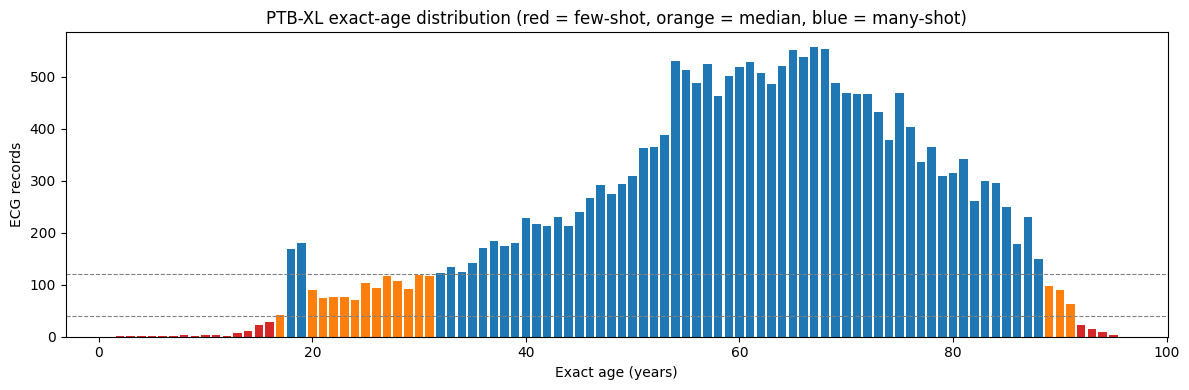

In [29]:
import matplotlib.pyplot as plt
age_counts = metadata_clean["age"].value_counts().sort_index().rename_axis("age").reset_index(name="records")
age_counts["shot_group"] = np.where(age_counts["records"] < 40, "few",
                           np.where(age_counts["records"] <= 120, "median", "many"))
age_counts.to_csv(REPORT_DIR / "exact_age_frequency_counts.csv", index=False)
display(age_counts.groupby("shot_group").agg(distinct_ages=("age", "count"), total_records=("records", "sum")))
display(metadata_clean["strat_fold"].value_counts().sort_index().rename("records").to_frame().T)

colors = age_counts["shot_group"].map({"few": "tab:red", "median": "tab:orange", "many": "tab:blue"})
plt.figure(figsize=(12, 4))
plt.bar(age_counts["age"], age_counts["records"], color=colors)
plt.axhline(40, ls="--", c="gray", lw=.8); plt.axhline(120, ls="--", c="gray", lw=.8)
plt.xlabel("Exact age (years)"); plt.ylabel("ECG records")
plt.title("PTB-XL exact-age distribution (red = few-shot, orange = median, blue = many-shot)")
plt.tight_layout(); plt.savefig(REPORT_DIR / "age_distribution.png", dpi=160); plt.show()

## 5. Validate waveforms (path existence for all records, content check on a sample)
Set `VALIDATE_ALL_WAVEFORMS = True` for a full pre-training audit.

In [45]:
import wfdb
def wf_exists(fn):
    b = DATASET_DIR / str(fn)
    return b.with_suffix(".dat").is_file() and b.with_suffix(".hea").is_file()

missing_wf = metadata_clean[~metadata_clean["filename_lr"].apply(wf_exists)]
missing_wf.to_csv(REPORT_DIR / "missing_waveform_files.csv", index=False)
print("Records with missing .dat/.hea:", len(missing_wf))

VALIDATE_ALL_WAVEFORMS = False
rows = metadata_clean if VALIDATE_ALL_WAVEFORMS else metadata_clean.sample(n=min(100, len(metadata_clean)), random_state=42)
bad = []
for r in rows.itertuples(index=False):
    try:
        s, f = wfdb.rdsamp(str(DATASET_DIR / r.filename_lr))
        if s.shape != (1000, 12) or float(f["fs"]) != 100.0 or not np.isfinite(s).all():
            bad.append((r.ecg_id, s.shape, f["fs"]))
    except Exception as e:
        bad.append((r.ecg_id, repr(e), None))
print(f"Checked {len(rows)} waveforms; problems: {len(bad)}", bad[:5])
if len(missing_wf) or bad:
    print("Do NOT train silently on these. The loader asserts on malformed waveforms; fix or document exclusions first.")

Records with missing .dat/.hea: 0
Checked 100 waveforms; problems: 0 []


## 6. Write model and training code to `code/`
These cells write the four source files (model, original training script, **v2 rare-age training script**, and the pooled-analysis script). Re-running overwrites them.

In [46]:
%%writefile code/ecgnextformer.py
"""
ECGNextFormer: reconstruction from the paper
"ECGNextFormer: A Lightweight, Scalable, and Explainable Architecture for
Estimating Cardiovascular Well-being from Electrocardiograms" (IEEE TAI, 2026).

This is a re-implementation from the paper text (Fig. 1-4, Table I, Eq. 1-8),
NOT the authors' official code.

Facts taken directly from the paper
-----------------------------------
* Stem: 2 temporal blocks  [Conv1D -> BatchNorm -> ReLU -> MaxPool(2)]
* Backbone: 2 ECGNext blocks [depthwise Conv1D -> LayerNorm -> 1x1 Conv (2C)
            -> GELU -> LayerNorm -> 1x1 Conv (K) -> MaxPool(2)]
* SLIM block: positional encoding -> LayerNorm -> bottleneck DropKey
  self-attention -> LayerNorm -> position-wise FFN -> multi-scale pooling
* Bottleneck attention (Fig. 4): input bottleneck D->D/r, Q/K/V expansion
  D/r->D split into h heads, DropKey (Bernoulli mask of -1e12 added to the
  scores before softmax), output bottleneck D->D/r, output expansion D/r->D
* Multi-scale pooling k=1,2,3,4 (adaptive avg pool, concat on length axis)
* Table I variant configs (Lite/Base/Plus/Max)

Choices the paper does NOT state (assumptions made here)
--------------------------------------------------------
* Positional encoding        -> depthwise Conv1D (k=3) added residually
                                (conditional positional encoding; has parameters)
* FFN hidden width           -> D // 4
* Residual connections around attention and FFN (pre-norm Transformer style)
* A third LayerNorm after the FFN, before multi-scale pooling
* Temporal-block convs have bias=False (they are followed by BatchNorm);
  every other Conv/Linear keeps PyTorch's default bias=True

How these were pinned down: I enumerated the unstated choices (biases, FFN
width, positional-encoding type, number of norms, BN affine) and kept the
combinations that reproduce the parameter counts in Table III of the paper for
ALL FOUR variants at once (Lite 11,089 / Base 38,561 / Plus 82,417 /
Max 142,657). Only two combinations did, and they share the structure above
(they differ only in where a single bias term sits, which has identical
parameter counts). Matching four counts exactly is strong evidence, but still
not proof, that this equals the authors' network.
"""

import math
from dataclasses import dataclass

import torch
import torch.nn as nn
import torch.nn.functional as F


# ----------------------------------------------------------------------------
# Table I of the paper
# ----------------------------------------------------------------------------
@dataclass(frozen=True)
class VariantConfig:
    stem_channels: int      # temporal blocks 1 & 2
    backbone_channels: int  # ECGNext blocks 1 & 2 == SLIM dimension D


VARIANTS = {
    "lite": VariantConfig(16, 32),
    "base": VariantConfig(32, 64),
    "plus": VariantConfig(48, 96),
    "max": VariantConfig(64, 128),
}


class TemporalBlock(nn.Module):
    """Fig. 2(A): Conv1D -> BatchNorm1D -> ReLU -> MaxPool."""

    def __init__(self, cin, cout, kernel_size, pool=2):
        super().__init__()
        self.conv = nn.Conv1d(cin, cout, kernel_size, padding=kernel_size // 2, bias=False)
        self.bn = nn.BatchNorm1d(cout)
        self.act = nn.ReLU(inplace=True)
        self.pool = nn.MaxPool1d(pool)

    def forward(self, x):
        return self.pool(self.act(self.bn(self.conv(x))))


class ChannelLayerNorm(nn.Module):
    """LayerNorm over the channel axis of a (B, C, L) tensor."""

    def __init__(self, channels):
        super().__init__()
        self.norm = nn.LayerNorm(channels)

    def forward(self, x):
        return self.norm(x.transpose(1, 2)).transpose(1, 2)


class ECGNextBlock(nn.Module):
    """Fig. 2(B): depthwise conv -> LN -> 1x1 (2C) -> GELU -> LN -> 1x1 (K) -> pool."""

    def __init__(self, cin, cout, kernel_size, pool=2):
        super().__init__()
        self.dw = nn.Conv1d(cin, cin, kernel_size, padding=kernel_size // 2, groups=cin)
        self.ln1 = ChannelLayerNorm(cin)
        self.pw_expand = nn.Conv1d(cin, 2 * cin, 1)
        self.act = nn.GELU()
        self.ln2 = ChannelLayerNorm(2 * cin)
        self.pw_project = nn.Conv1d(2 * cin, cout, 1)
        self.pool = nn.MaxPool1d(pool)

    def forward(self, x):
        x = self.ln1(self.dw(x))
        x = self.ln2(self.act(self.pw_expand(x)))
        return self.pool(self.pw_project(x))


class BottleneckDropKeyAttention(nn.Module):
    """Fig. 4. Input/output bottlenecks + DropKey (dropout-before-softmax)."""

    def __init__(self, dim, ratio=8, heads=4, dropkey=0.6):
        super().__init__()
        assert dim % heads == 0 and dim % ratio == 0
        self.dim, self.heads, self.dropkey = dim, heads, dropkey
        self.head_dim = dim // heads
        b = dim // ratio
        self.in_bottleneck = nn.Linear(dim, b)
        self.q = nn.Linear(b, dim)
        self.k = nn.Linear(b, dim)
        self.v = nn.Linear(b, dim)
        self.out_bottleneck = nn.Linear(dim, b)
        self.out_proj = nn.Linear(b, dim)

    def _split(self, t):
        B, L, _ = t.shape
        return t.view(B, L, self.heads, self.head_dim).transpose(1, 2)  # B,h,L,d

    def forward(self, x):
        B, L, _ = x.shape
        z = self.in_bottleneck(x)
        q, k, v = self._split(self.q(z)), self._split(self.k(z)), self._split(self.v(z))
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.head_dim)  # B,h,L,L
        if self.training and self.dropkey > 0:
            drop = torch.rand_like(scores) < self.dropkey
            scores = scores + drop.to(scores.dtype) * (-1e12)  # paper: -10^12 mask
        attn = torch.softmax(scores, dim=-1)
        out = (attn @ v).transpose(1, 2).reshape(B, L, self.dim)
        return self.out_proj(self.out_bottleneck(out))


class MultiScalePooling(nn.Module):
    """Eq. 5: concat of adaptive average pools to k_1..k_n along length."""

    def __init__(self, scales=(1, 2, 3, 4)):
        super().__init__()
        self.scales = tuple(scales)

    def forward(self, x):  # x: (B, L, D)
        x = x.transpose(1, 2)  # B, D, L
        pooled = [F.adaptive_avg_pool1d(x, k) for k in self.scales]
        return torch.cat(pooled, dim=2)  # B, D, sum(k)


class SLIMBlock(nn.Module):
    """Fig. 3(A): PE -> LN -> attention -> LN -> FFN -> (LN) -> MSP."""

    def __init__(self, dim, ratio=8, heads=4, dropkey=0.6, ffn_hidden=None,
                 scales=(1, 2, 3, 4)):
        super().__init__()
        ffn_hidden = ffn_hidden or dim // 4
        # positional encoding: depthwise conv over the length axis
        self.pos = nn.Conv1d(dim, dim, 3, padding=1, groups=dim)
        self.ln1 = nn.LayerNorm(dim)
        self.attn = BottleneckDropKeyAttention(dim, ratio, heads, dropkey)
        self.ln2 = nn.LayerNorm(dim)
        self.ffn = nn.Sequential(
            nn.Linear(dim, ffn_hidden), nn.GELU(), nn.Linear(ffn_hidden, dim)
        )
        self.ln3 = nn.LayerNorm(dim)  # assumption: final norm before pooling
        self.msp = MultiScalePooling(scales)

    def forward(self, x):  # x: (B, L, D)
        x = x + self.pos(x.transpose(1, 2)).transpose(1, 2)
        x = x + self.attn(self.ln1(x))
        x = x + self.ffn(self.ln2(x))
        x = self.ln3(x)
        return self.msp(x)  # B, D, sum(scales)


class ECGNextFormer(nn.Module):
    """Input: (B, 12, L) -> output: (B,) predicted age."""

    def __init__(self, variant="lite", in_leads=12, dropkey=0.6, ratio=8,
                 heads=4, ffn_hidden=None, scales=(1, 2, 3, 4)):
        super().__init__()
        cfg = VARIANTS[variant.lower()]
        c, d = cfg.stem_channels, cfg.backbone_channels
        self.temporal1 = TemporalBlock(in_leads, c, 7)
        self.temporal2 = TemporalBlock(c, c, 5)
        self.ecgnext1 = ECGNextBlock(c, d, 5)
        self.ecgnext2 = ECGNextBlock(d, d, 3)
        self.slim = SLIMBlock(d, ratio, heads, dropkey, ffn_hidden, scales)
        self.head = nn.Linear(d * sum(scales), 1)  # "MSP dim" in Table I

    def forward(self, x):
        x = self.ecgnext2(self.ecgnext1(self.temporal2(self.temporal1(x))))
        x = self.slim(x.transpose(1, 2))
        return self.head(x.flatten(1)).squeeze(-1)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Parameter counts reported in Table III of the paper
PAPER_PARAMS = {"lite": 11089, "base": 38561, "plus": 82417, "max": 142657}


if __name__ == "__main__":
    for name in VARIANTS:
        m = ECGNextFormer(name)
        y = m(torch.randn(2, 12, 800))
        print(f"{name:5s} params={count_parameters(m):>8,}  "
              f"paper={PAPER_PARAMS[name]:>8,}  out={tuple(y.shape)}")

Overwriting code/ecgnextformer.py


In [47]:
%%writefile code/train_ecgnextformer.py
"""
Training / evaluation pipeline for ECGNextFormer age estimation on PTB-XL.

Follows the paper's protocol (Sec. III-B/C):
  * 100 Hz signals, MSE loss, 200 epochs, batch 96, lr 1e-3, /10 every 75 epochs
  * 8-second random crops for training
  * best checkpoint chosen by validation MSE
  * 10 sliding 8-second windows averaged at inference ("multi-shot")
  * official PTB-XL strat_fold column; metrics MSE / MAE / GM on all, many-shot
    (>120 samples per age), median-shot (40-120) and few-shot (<40) subsets
  * 10-fold cross-validation (or any subset of folds)

Two loss options, everything else identical, so the comparison is fair:
  --loss mse     standard MSE (paper baseline)
  --loss tamse   Tail-Aware Weighted MSE (see TailAwareWeights below)

Usage examples
--------------
  # sanity check without any data (synthetic signals)
  python train_ecgnextformer.py --synthetic --epochs 3 --folds 10 --variant lite

  # one fold, baseline vs proposed, on your extracted PTB-XL folder
  python train_ecgnextformer.py --dataset_dir "C:/.../ptb-xl-...-1.0.1" --loss mse   --folds 10
  python train_ecgnextformer.py --dataset_dir "C:/.../ptb-xl-...-1.0.1" --loss tamse --folds 10

  # full 10-fold CV (final numbers)
  python train_ecgnextformer.py --dataset_dir ... --loss mse   --folds all
  python train_ecgnextformer.py --dataset_dir ... --loss tamse --folds all
"""

import argparse
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from ecgnextformer import ECGNextFormer, count_parameters

SIG_LEN = 1000   # 10 s @ 100 Hz
CROP = 800       # 8 s
MAX_AGE_VALID = 100  # PTB-XL stores ages > 89 as 300 (anonymised); drop them


# ----------------------------------------------------------------------------
# Data
# ----------------------------------------------------------------------------
def load_ptbxl(dataset_dir, cache_dir, max_records=None):
    """Return (metadata_df, signals[N,1000,12] float32). Cached as .npy."""
    import wfdb  # imported lazily so --synthetic works without it

    dataset_dir, cache_dir = Path(dataset_dir), Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    meta = pd.read_csv(dataset_dir / "ptbxl_database.csv")
    meta = meta.dropna(subset=["age", "filename_lr", "strat_fold"])
    meta = meta[(meta["age"] > 0) & (meta["age"] <= MAX_AGE_VALID)].reset_index(drop=True)
    if max_records:
        meta = meta.iloc[:max_records].copy()

    sig_path = cache_dir / f"ptbxl_lr_signals_{len(meta)}.npy"
    ids_path = cache_dir / f"ptbxl_lr_ids_{len(meta)}.npy"
    if sig_path.exists() and ids_path.exists() and \
            (np.load(ids_path) == meta["ecg_id"].to_numpy()).all():
        print(f"Loading cached signals: {sig_path}")
        return meta, np.load(sig_path, mmap_mode=None)

    print(f"Reading {len(meta)} waveforms with wfdb (one-time, then cached)...")
    sigs = np.zeros((len(meta), SIG_LEN, 12), dtype=np.float32)
    t0 = time.time()
    for i, fn in enumerate(meta["filename_lr"]):
        s, f = wfdb.rdsamp(str(dataset_dir / fn))
        assert s.shape == (SIG_LEN, 12) and f["fs"] == 100, (fn, s.shape, f["fs"])
        sigs[i] = s
        if (i + 1) % 2000 == 0:
            print(f"  {i + 1}/{len(meta)}  ({time.time() - t0:.0f}s)")
    sigs = np.nan_to_num(sigs)
    np.save(sig_path, sigs)
    np.save(ids_path, meta["ecg_id"].to_numpy())
    return meta, sigs


def make_synthetic(n=3000, seed=0):
    """Fake ECG-like data whose waveform depends weakly on age (pipeline test)."""
    rng = np.random.default_rng(seed)
    age = np.clip(rng.normal(60, 17, n), 2, 95).round()
    t = np.arange(SIG_LEN) / 100.0
    sigs = np.zeros((n, SIG_LEN, 12), dtype=np.float32)
    for i in range(n):
        hr = 1.0 + 0.003 * (age[i] - 60) + 0.05 * rng.standard_normal()
        base = np.sin(2 * np.pi * hr * t) ** 15
        for l in range(12):
            sigs[i, :, l] = (0.5 + 0.02 * l) * base * (1 + 0.01 * (age[i] - 60) / 10) \
                            + 0.05 * rng.standard_normal(SIG_LEN)
    meta = pd.DataFrame({
        "ecg_id": np.arange(n), "age": age,
        "strat_fold": (np.arange(n) % 10) + 1,
    })
    return meta, sigs


# ----------------------------------------------------------------------------
# Shot groups (paper: few <40, median 40-120, many >120 instances per age)
# ----------------------------------------------------------------------------
def shot_group_of_ages(ages, counts_by_age):
    c = np.array([counts_by_age.get(int(a), 0) for a in ages])
    g = np.where(c < 40, "few", np.where(c <= 120, "median", "many"))
    return g


# ----------------------------------------------------------------------------
# Tail-Aware Weighted MSE
# ----------------------------------------------------------------------------
class TailAwareWeights:
    """Gaussian-smoothed inverse-frequency weights for training ages.

    The raw inverse-frequency weights are normalized to have mean 1 across
    training examples, then clipped to [1/clip, clip]. Because clipping can
    change the mean, the final weights are not guaranteed to have mean exactly
    1; this version prioritizes enforcing the requested bounds.

    Weights are derived from training-fold ages only, avoiding validation/test
    label leakage. This is a proposed tail-aware weighting method, not a claim
    that the original ECGNextFormer paper uses this loss.
    """

    def __init__(self, train_ages, alpha=0.5, sigma=2.0, clip=5.0, max_age=120):
        train_ages = np.asarray(train_ages).astype(int)
        if train_ages.size == 0:
            raise ValueError("train_ages must not be empty")
        if alpha < 0:
            raise ValueError("alpha must be >= 0")
        if sigma <= 0:
            raise ValueError("sigma must be > 0")
        if clip < 1:
            raise ValueError("clip must be >= 1")
        if np.any(train_ages < 0) or np.any(train_ages > max_age):
            raise ValueError(f"Training ages must be in [0, {max_age}]")

        counts = np.bincount(train_ages, minlength=max_age + 1).astype(float)

        # Smooth counts across neighbouring ages with a Gaussian kernel.
        radius = int(4 * sigma)
        offsets = np.arange(-radius, radius + 1, dtype=float)
        kernel = np.exp(-0.5 * (offsets / sigma) ** 2)
        kernel /= kernel.sum()
        smooth = np.convolve(counts, kernel, mode="same")
        smooth = np.maximum(smooth, 1e-3)

        weights = smooth ** (-alpha)

        # Normalize the average weight over training examples to 1 first.
        mean_weight = float(weights[train_ages].mean())
        weights = weights / max(mean_weight, 1e-12)

        # Clip AFTER normalization. Do not renormalize afterward, because that
        # could move values outside the specified clipping interval.
        weights = np.clip(weights, 1.0 / clip, clip)

        self.table = torch.tensor(weights, dtype=torch.float32)
        train_weights = weights[train_ages]
        print(
            "TAMSE weights | "
            f"train mean={train_weights.mean():.4f} | "
            f"train min={train_weights.min():.4f} | "
            f"train max={train_weights.max():.4f} | "
            f"configured bounds=[{1.0 / clip:.4f}, {clip:.4f}]"
        )

    def weights_for(self, ages_tensor):
        indices = ages_tensor.long().clamp(0, len(self.table) - 1)
        return self.table.to(ages_tensor.device)[indices]


# ----------------------------------------------------------------------------
# Batching (all data lives in RAM; crops done on the fly)
# ----------------------------------------------------------------------------
def batch_iterator(X, y, idx, batch_size, crop_mode, rng=None):
    """X: torch (N,1000,12). crop_mode: 'random' or 'center'."""
    ar = torch.arange(CROP)
    for s in range(0, len(idx), batch_size):
        b = idx[s:s + batch_size]
        xb = X[b]  # (B,1000,12) copy
        if crop_mode == "random":
            starts = torch.from_numpy(rng.integers(0, SIG_LEN - CROP + 1, size=len(b)))
        else:
            starts = torch.full((len(b),), (SIG_LEN - CROP) // 2)
        gather_idx = (starts[:, None] + ar[None, :])[:, :, None].expand(-1, -1, 12)
        xb = torch.gather(xb, 1, gather_idx).transpose(1, 2).contiguous()  # B,12,800
        yield xb, y[b]


@torch.no_grad()
def predict(model, X, idx, device, n_shots=1, batch_size=256):
    """n_shots=1 -> centre crop; n_shots>1 -> evenly spaced sliding windows, averaged."""
    model.eval()
    ar = torch.arange(CROP)
    starts_list = ([(SIG_LEN - CROP) // 2] if n_shots == 1
                   else np.linspace(0, SIG_LEN - CROP, n_shots).round().astype(int).tolist())
    out = []
    for s in range(0, len(idx), batch_size):
        b = idx[s:s + batch_size]
        xb_full = X[b]
        acc = 0.0
        for st in starts_list:
            xb = xb_full[:, st:st + CROP, :].transpose(1, 2).contiguous().to(device)
            acc = acc + model(xb).float().cpu()
        out.append(acc / len(starts_list))
    return torch.cat(out)


# ----------------------------------------------------------------------------
# Metrics
# ----------------------------------------------------------------------------
def age_metrics(y_true, y_pred, groups):
    err = y_pred - y_true
    res = {}
    for name, mask in [("all", np.ones_like(err, dtype=bool)),
                       ("many", groups == "many"),
                       ("median", groups == "median"),
                       ("few", groups == "few")]:
        if mask.sum() == 0:
            res.update({f"MSE_{name}": np.nan, f"MAE_{name}": np.nan, f"GM_{name}": np.nan,
                        f"n_{name}": 0})
            continue
        e = err[mask]
        res[f"MSE_{name}"] = float(np.mean(e ** 2))
        res[f"MAE_{name}"] = float(np.mean(np.abs(e)))
        res[f"GM_{name}"] = float(np.exp(np.mean(np.log(np.abs(e) + 1e-6))))
        res[f"n_{name}"] = int(mask.sum())
    return res


# ----------------------------------------------------------------------------
# One fold
# ----------------------------------------------------------------------------
def run_fold(args, meta, X_all, test_fold, device, out_dir):
    folds = meta["strat_fold"].to_numpy().astype(int)
    val_fold = (test_fold - 2) % 10 + 1  # fold 10 -> val 9, fold 1 -> val 10
    tr_idx = np.where((folds != test_fold) & (folds != val_fold))[0]
    va_idx = np.where(folds == val_fold)[0]
    te_idx = np.where(folds == test_fold)[0]
    ages = meta["age"].to_numpy().astype(np.float32)

    # Patient-level leakage check (official folds should already guarantee it)
    if "patient_id" in meta.columns:
        pid = meta["patient_id"].to_numpy()
        shared = set(pid[tr_idx]) & (set(pid[va_idx]) | set(pid[te_idx]))
        assert not shared, f"patient overlap across splits: {len(shared)}"

    # Normalisation + target scaling from TRAINING data only
    mu = X_all[tr_idx].reshape(-1, 12).mean(0)
    sd = X_all[tr_idx].reshape(-1, 12).std(0) + 1e-6
    Xn = ((X_all - mu) / sd).astype(np.float32)
    X = torch.from_numpy(Xn)
    age_mu, age_sd = float(ages[tr_idx].mean()), float(ages[tr_idx].std())
    y = torch.from_numpy((ages - age_mu) / age_sd)  # standardised target
    y_years = torch.from_numpy(ages)

    # Shot groups: counts over the whole dataset (paper) or training split only
    count_src = ages if args.shot_counts == "all" else ages[tr_idx]
    vals, cnts = np.unique(count_src.astype(int), return_counts=True)
    counts_by_age = dict(zip(vals.tolist(), cnts.tolist()))
    groups_test = shot_group_of_ages(ages[te_idx], counts_by_age)
    groups_val = shot_group_of_ages(ages[va_idx], counts_by_age)

    weigher = None
    if args.loss == "tamse":
        weigher = TailAwareWeights(ages[tr_idx], alpha=args.alpha, sigma=args.sigma,
                                   clip=args.clip)

    torch.manual_seed(args.seed + test_fold)
    rng = np.random.default_rng(args.seed + test_fold)
    model = ECGNextFormer(args.variant, dropkey=args.dropkey).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=args.lr)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=args.lr_step, gamma=0.1)
    print(f"\n=== fold {test_fold} | val {val_fold} | loss={args.loss} | "
          f"train {len(tr_idx)} / val {len(va_idx)} / test {len(te_idx)} | "
          f"params {count_parameters(model):,} ===")

    best_val, best_state, hist = float("inf"), None, []
    for epoch in range(1, args.epochs + 1):
        model.train()
        perm = rng.permutation(tr_idx)
        tot, nseen = 0.0, 0
        for xb, yb in batch_iterator(X, y, perm, args.batch_size, "random", rng):
            xb, yb = xb.to(device), yb.to(device)
            pred = model(xb)
            per = (pred - yb) ** 2
            if weigher is not None:
                yrs = yb * age_sd + age_mu
                per = per * weigher.weights_for(torch.round(yrs))
            loss = per.mean()
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            tot += loss.item() * len(yb)
            nseen += len(yb)
        sched.step()

        # validation (plain MSE in years, centre crop) -> checkpoint selection
        vp = predict(model, X, va_idx, device, n_shots=1) * age_sd + age_mu
        val_mse = float(((vp - y_years[va_idx]) ** 2).mean())
        hist.append({"epoch": epoch, "train_loss": tot / nseen, "val_mse": val_mse})
        if val_mse < best_val:
            best_val = val_mse
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if epoch == 1 or epoch % args.log_every == 0 or epoch == args.epochs:
            print(f"epoch {epoch:3d} | train {tot / nseen:8.4f} | val MSE {val_mse:7.2f} "
                  f"| best {best_val:7.2f}")

    model.load_state_dict(best_state)
    results = []
    for shots in (1, 10):
        tp = predict(model, X, te_idx, device, n_shots=shots) * age_sd + age_mu
        m = age_metrics(ages[te_idx], tp.numpy(), groups_test)
        m.update({"fold": test_fold, "loss": args.loss, "variant": args.variant,
                  "shots": shots, "best_val_mse": best_val,
                  "params": count_parameters(model)})
        results.append(m)
        print(f"test | {shots:2d}-shot | MSE all {m['MSE_all']:.2f} | many {m['MSE_many']:.2f} "
              f"| median {m['MSE_median']:.2f} | few {m['MSE_few']:.2f} | MAE {m['MAE_all']:.2f}")

    tag = f"{args.variant}_{args.loss}_fold{test_fold}"
    torch.save({"state_dict": best_state, "age_mu": age_mu, "age_sd": age_sd,
                "x_mu": mu, "x_sd": sd, "args": vars(args)}, out_dir / f"{tag}_best.pt")
    pd.DataFrame(hist).to_csv(out_dir / f"{tag}_history.csv", index=False)
    return results


# ----------------------------------------------------------------------------
def parse_args():
    p = argparse.ArgumentParser()
    p.add_argument("--dataset_dir", type=str, default=None,
                   help="folder containing ptbxl_database.csv and records100/")
    p.add_argument("--cache_dir", type=str, default="./cache")
    p.add_argument("--out_dir", type=str, default="./runs")
    p.add_argument("--synthetic", action="store_true", help="use fake data (pipeline test)")
    p.add_argument("--max_records", type=int, default=None, help="debug: limit records")
    p.add_argument("--variant", default="lite", choices=["lite", "base", "plus", "max"])
    p.add_argument("--loss", default="mse", choices=["mse", "tamse"])
    p.add_argument("--folds", default="10", help="e.g. 10 | 9,10 | all")
    p.add_argument("--epochs", type=int, default=200)
    p.add_argument("--batch_size", type=int, default=96)
    p.add_argument("--lr", type=float, default=1e-3)
    p.add_argument("--lr_step", type=int, default=75)
    p.add_argument("--dropkey", type=float, default=0.6)
    p.add_argument("--shot_counts", default="all", choices=["all", "train"],
                   help="count ages over whole dataset (paper) or the training split")
    p.add_argument("--alpha", type=float, default=0.5, help="tamse: weight exponent")
    p.add_argument("--sigma", type=float, default=2.0, help="tamse: kernel smoothing (years)")
    p.add_argument("--clip", type=float, default=5.0, help="tamse: max weight ratio")
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--log_every", type=int, default=10)
    return p.parse_args()


def main():
    args = parse_args()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("device:", device)
    out_dir = Path(args.out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    if args.synthetic:
        meta, sigs = make_synthetic()
    else:
        assert args.dataset_dir, "--dataset_dir is required (or use --synthetic)"
        meta, sigs = load_ptbxl(args.dataset_dir, args.cache_dir, args.max_records)
    print(f"records: {len(meta)} | signals {sigs.shape} | "
          f"age range {meta['age'].min():.0f}-{meta['age'].max():.0f}")

    folds = list(range(1, 11)) if args.folds == "all" else [int(f) for f in args.folds.split(",")]
    all_res = []
    for f in folds:
        all_res += run_fold(args, meta, sigs, f, device, out_dir)
        pd.DataFrame(all_res).to_csv(out_dir / f"results_{args.variant}_{args.loss}.csv",
                                     index=False)

    df = pd.DataFrame(all_res)
    cols = [c for c in df.columns if c.startswith(("MSE", "MAE", "GM"))]
    summary = df.groupby("shots")[cols].agg(["mean", "std"])
    summary.to_csv(out_dir / f"summary_{args.variant}_{args.loss}.csv")
    print("\n=== Mean over folds ===")
    print(df.groupby("shots")[cols].mean().round(2).T)


if __name__ == "__main__":
    main()

Overwriting code/train_ecgnextformer.py


In [30]:
%%writefile code/train_ecgnextformer_v2.py
"""
train_ecgnextformer_v2.py  --  rare-age (few-shot) improvements for ECGNextFormer.

Drop-in companion to train_ecgnextformer.py (keep that file in the same folder;
this one imports its data loading, batching, prediction and metric functions so
the baseline is untouched).

What is new
-----------
--loss      mse | tamse | gai | bmc
              gai = Balanced MSE, GAI form (Ren et al., CVPR 2022): uses the
                    training-age prior (smoothed) inside a softmax over ages.
              bmc = Balanced MSE, batch-based form (no prior needed; use batch>=64).
--sampler   uniform | balanced     balanced = draw training ECGs with prob ~ count^-beta
--select    mse | balanced         checkpoint selection metric. 'balanced' = mean of
              per-shot-group validation MAE (many / median / few). Plain val MSE is
              dominated by many-shot ages and therefore prefers checkpoints that
              under-serve the tails.
--aug       light ECG augmentation (amplitude scale, noise, baseline wander).
              Recommended together with --sampler balanced (otherwise the same rare
              ECGs are replayed identically and the model memorises them).
Test-set predictions are saved (preds_*.csv) so results can be POOLED across folds
(see analyze_pooled.py). Per-fold few-shot sets are only ~10-20 ECGs: far too small
to compare methods on.

Examples
--------
  python train_ecgnextformer_v2.py --dataset_dir ... --loss gai  --select balanced --folds all --epochs 100 --batch_size 96 --run_name gai_bal
  python train_ecgnextformer_v2.py --dataset_dir ... --loss mse  --sampler balanced --aug --select balanced --folds all --epochs 100 --batch_size 96 --run_name samp_aug
  python train_ecgnextformer_v2.py --dataset_dir ... --loss mse  --select mse --folds all --epochs 100 --batch_size 96 --run_name baseline
"""

import argparse
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from ecgnextformer import ECGNextFormer, count_parameters
from train_ecgnextformer import (  # reuse, do not duplicate
    load_ptbxl, make_synthetic, shot_group_of_ages, TailAwareWeights,
    batch_iterator, predict, age_metrics,
)

MAX_AGE = 120


# ----------------------------------------------------------------------------
def smooth_age_counts(train_ages, sigma=2.0, max_age=MAX_AGE):
    """Gaussian-smoothed per-integer-age counts from TRAINING ages only."""
    counts = np.bincount(np.asarray(train_ages).astype(int), minlength=max_age + 1).astype(float)
    radius = int(4 * sigma)
    off = np.arange(-radius, radius + 1, dtype=float)
    k = np.exp(-0.5 * (off / sigma) ** 2)
    k /= k.sum()
    return np.maximum(np.convolve(counts, k, mode="same"), 1e-3)


# ----------------------------------------------------------------------------
# Balanced MSE (Ren et al. 2022)
# ----------------------------------------------------------------------------
class BalancedMSE(nn.Module):
    """
    gai: logits_j = -(pred - y_j)^2 / (2 s^2) + log p_train(y_j), CE against the true age bin.
    bmc: same, but the 'classes' are the targets in the current batch (no prior).
    Loss is multiplied by (2 s^2).detach() as in the reference implementation.
    Everything is in standardised-target units. s is learned (its own optimiser group).
    """

    def __init__(self, mode, age_mu, age_sd, train_ages, prior_sigma=2.0, init_sigma=0.5):
        super().__init__()
        assert mode in ("gai", "bmc")
        self.mode = mode
        self.log_sigma = nn.Parameter(torch.tensor(float(np.log(init_sigma))))
        if mode == "gai":
            sm = smooth_age_counts(train_ages, prior_sigma)
            prior = sm / sm.sum()
            self.register_buffer("log_prior", torch.log(torch.tensor(prior, dtype=torch.float32)))
            bins = (np.arange(MAX_AGE + 1) - age_mu) / age_sd
            self.register_buffer("bins", torch.tensor(bins, dtype=torch.float32))

    def forward(self, pred, target_std, target_age):
        var2 = 2.0 * torch.exp(2.0 * self.log_sigma)
        if self.mode == "gai":
            logits = -(pred[:, None] - self.bins[None, :]) ** 2 / var2 + self.log_prior[None, :]
            labels = target_age.long().clamp(0, MAX_AGE)
        else:
            logits = -(pred[:, None] - target_std[None, :]) ** 2 / var2
            labels = torch.arange(len(pred), device=pred.device)
        return F.cross_entropy(logits, labels) * var2.detach()


# ----------------------------------------------------------------------------
# Augmentation (training batches only; xb is standardised, shape B,12,L)
# ----------------------------------------------------------------------------
def augment(xb, strength=1.0):
    B, C, L = xb.shape
    dev = xb.device
    xb = xb * (1.0 + 0.10 * strength * (torch.rand(B, 1, 1, device=dev) * 2 - 1))  # amplitude
    xb = xb + 0.03 * strength * torch.randn_like(xb)                                  # sensor noise
    t = torch.linspace(0, 1, L, device=dev)[None, None, :]
    cycles = 0.4 + 3.6 * torch.rand(B, 1, 1, device=dev)          # ~0.05-0.5 Hz over 8 s
    phase = 2 * np.pi * torch.rand(B, 1, 1, device=dev)
    lead_gain = 0.5 + 0.5 * torch.rand(B, C, 1, device=dev)
    return xb + 0.10 * strength * lead_gain * torch.sin(2 * np.pi * cycles * t + phase)  # wander


def balanced_mae(abs_err, groups):
    vals = [abs_err[groups == g].mean() for g in ("many", "median", "few") if (groups == g).any()]
    return float(np.mean(vals))


# ----------------------------------------------------------------------------
def run_fold(args, meta, X_all, test_fold, device, out_dir):
    folds = meta["strat_fold"].to_numpy().astype(int)
    val_fold = (test_fold - 2) % 10 + 1
    tr_idx = np.where((folds != test_fold) & (folds != val_fold))[0]
    va_idx = np.where(folds == val_fold)[0]
    te_idx = np.where(folds == test_fold)[0]
    ages = meta["age"].to_numpy().astype(np.float32)

    if "patient_id" in meta.columns:
        pid = meta["patient_id"].to_numpy()
        shared = set(pid[tr_idx]) & (set(pid[va_idx]) | set(pid[te_idx]))
        assert not shared, f"patient overlap across splits: {len(shared)}"

    mu = X_all[tr_idx].reshape(-1, 12).mean(0)
    sd = X_all[tr_idx].reshape(-1, 12).std(0) + 1e-6
    X = torch.from_numpy(((X_all - mu) / sd).astype(np.float32))
    age_mu, age_sd = float(ages[tr_idx].mean()), float(ages[tr_idx].std())
    y = torch.from_numpy((ages - age_mu) / age_sd)
    y_years = torch.from_numpy(ages)

    count_src = ages if args.shot_counts == "all" else ages[tr_idx]
    vals, cnts = np.unique(count_src.astype(int), return_counts=True)
    counts_by_age = dict(zip(vals.tolist(), cnts.tolist()))
    groups_test = shot_group_of_ages(ages[te_idx], counts_by_age)
    groups_val = shot_group_of_ages(ages[va_idx], counts_by_age)

    # ---- loss
    weigher, crit = None, None
    if args.loss == "tamse":
        weigher = TailAwareWeights(ages[tr_idx], alpha=args.alpha, sigma=args.sigma, clip=args.clip)
    elif args.loss in ("gai", "bmc"):
        crit = BalancedMSE(args.loss, age_mu, age_sd, ages[tr_idx], args.sigma,
                           args.noise_sigma).to(device)
    if args.sampler == "balanced" and args.loss != "mse":
        print("WARNING: balanced sampler + a re-balancing loss double-corrects the imbalance. "
              "Use the sampler with --loss mse.")

    # ---- sampler probabilities (training ages only)
    p_samp = None
    if args.sampler == "balanced":
        sm = smooth_age_counts(ages[tr_idx], args.sigma)
        w = sm[ages[tr_idx].astype(int)] ** (-args.beta)
        p_samp = w / w.sum()

    torch.manual_seed(args.seed + test_fold)
    rng = np.random.default_rng(args.seed + test_fold)
    model = ECGNextFormer(args.variant, dropkey=args.dropkey).to(device)
    groups_opt = [{"params": model.parameters(), "lr": args.lr}]
    if crit is not None:
        groups_opt.append({"params": crit.parameters(), "lr": 1e-2})
    opt = torch.optim.Adam(groups_opt)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=args.lr_step, gamma=0.1)
    print(f"\n=== fold {test_fold} | val {val_fold} | run={args.run_name} loss={args.loss} "
          f"sampler={args.sampler} select={args.select} aug={args.aug} | "
          f"train {len(tr_idx)} / val {len(va_idx)} / test {len(te_idx)} | "
          f"params {count_parameters(model):,} ===")

    best_score, best_state, hist = float("inf"), None, []
    for epoch in range(1, args.epochs + 1):
        model.train()
        perm = (rng.permutation(tr_idx) if p_samp is None
                else rng.choice(tr_idx, size=len(tr_idx), replace=True, p=p_samp))
        tot, nseen = 0.0, 0
        for xb, yb in batch_iterator(X, y, perm, args.batch_size, "random", rng):
            xb, yb = xb.to(device), yb.to(device)
            if args.aug:
                xb = augment(xb, args.aug_strength)
            pred = model(xb)
            yrs = torch.round(yb * age_sd + age_mu)
            if crit is not None:
                loss = crit(pred, yb, yrs)
            else:
                per = (pred - yb) ** 2
                if weigher is not None:
                    per = per * weigher.weights_for(yrs)
                loss = per.mean()
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            tot += loss.item() * len(yb)
            nseen += len(yb)
        sched.step()

        vp = (predict(model, X, va_idx, device, n_shots=1) * age_sd + age_mu).numpy()
        verr = vp - ages[va_idx]
        val_mse = float(np.mean(verr ** 2))
        val_bal = balanced_mae(np.abs(verr), groups_val)
        score = val_mse if args.select == "mse" else val_bal
        hist.append({"epoch": epoch, "train_loss": tot / nseen, "val_mse": val_mse,
                     "val_balanced_mae": val_bal})
        if score < best_score:
            best_score = score
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if epoch == 1 or epoch % args.log_every == 0 or epoch == args.epochs:
            print(f"epoch {epoch:3d} | train {tot / nseen:8.4f} | val MSE {val_mse:7.2f} "
                  f"| val balMAE {val_bal:6.2f} | best({args.select}) {best_score:7.2f}")

    model.load_state_dict(best_state)
    results, pred_rows = [], []
    for shots in (1, 10):
        tp = (predict(model, X, te_idx, device, n_shots=shots) * age_sd + age_mu).numpy()
        m = age_metrics(ages[te_idx], tp, groups_test)
        m.update({"fold": test_fold, "run": args.run_name, "loss": args.loss, "variant": args.variant,
                  "shots": shots, "best_score": best_score, "params": count_parameters(model)})
        results.append(m)
        print(f"test | {shots:2d}-shot | MSE all {m['MSE_all']:.2f} | many {m['MSE_many']:.2f} "
              f"| median {m['MSE_median']:.2f} | few {m['MSE_few']:.2f} | MAE {m['MAE_all']:.2f} "
              f"| MAE few {m['MAE_few']:.2f} (n_few={m['n_few']})")
        pred_rows.append(pd.DataFrame({
            "ecg_id": meta["ecg_id"].to_numpy()[te_idx], "fold": test_fold, "shots": shots,
            "age": ages[te_idx], "pred": tp, "group": groups_test}))

    tag = f"{args.variant}_{args.run_name}_fold{test_fold}"
    torch.save({"state_dict": best_state, "age_mu": age_mu, "age_sd": age_sd,
                "x_mu": mu, "x_sd": sd, "args": vars(args)}, out_dir / f"{tag}_best.pt")
    pd.DataFrame(hist).to_csv(out_dir / f"{tag}_history.csv", index=False)
    return results, pd.concat(pred_rows)


# ----------------------------------------------------------------------------
def parse_args():
    p = argparse.ArgumentParser()
    p.add_argument("--dataset_dir", type=str, default=None)
    p.add_argument("--cache_dir", type=str, default="./cache")
    p.add_argument("--out_dir", type=str, default="./runs_v2")
    p.add_argument("--run_name", type=str, default=None, help="default: the loss name")
    p.add_argument("--synthetic", action="store_true")
    p.add_argument("--max_records", type=int, default=None)
    p.add_argument("--variant", default="lite", choices=["lite", "base", "plus", "max"])
    p.add_argument("--loss", default="mse", choices=["mse", "tamse", "gai", "bmc"])
    p.add_argument("--sampler", default="uniform", choices=["uniform", "balanced"])
    p.add_argument("--beta", type=float, default=0.5, help="sampler: prob ~ count^-beta (1 = fully balanced)")
    p.add_argument("--select", default="balanced", choices=["mse", "balanced"])
    p.add_argument("--aug", action="store_true")
    p.add_argument("--aug_strength", type=float, default=1.0)
    p.add_argument("--folds", default="10")
    p.add_argument("--epochs", type=int, default=100)
    p.add_argument("--batch_size", type=int, default=96)
    p.add_argument("--lr", type=float, default=1e-3)
    p.add_argument("--lr_step", type=int, default=40, help="LR /10 every N epochs (paper: 75 of 200)")
    p.add_argument("--dropkey", type=float, default=0.6)
    p.add_argument("--shot_counts", default="all", choices=["all", "train"])
    p.add_argument("--alpha", type=float, default=0.5, help="tamse: weight exponent")
    p.add_argument("--sigma", type=float, default=2.0, help="label smoothing width (years)")
    p.add_argument("--clip", type=float, default=5.0, help="tamse: max weight ratio")
    p.add_argument("--noise_sigma", type=float, default=0.5, help="gai/bmc: initial noise std (standardised units)")
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--log_every", type=int, default=10)
    a = p.parse_args()
    a.run_name = a.run_name or a.loss
    return a


def main():
    args = parse_args()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("device:", device)
    out_dir = Path(args.out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    if args.synthetic:
        meta, sigs = make_synthetic()
    else:
        assert args.dataset_dir, "--dataset_dir is required (or use --synthetic)"
        meta, sigs = load_ptbxl(args.dataset_dir, args.cache_dir, args.max_records)
    print(f"records: {len(meta)} | signals {sigs.shape}")

    folds = list(range(1, 11)) if args.folds == "all" else [int(f) for f in args.folds.split(",")]
    all_res, all_pred = [], []
    for f in folds:
        r, pr = run_fold(args, meta, sigs, f, device, out_dir)
        all_res += r
        all_pred.append(pr)
        pd.DataFrame(all_res).to_csv(out_dir / f"results_{args.variant}_{args.run_name}.csv", index=False)
        pd.concat(all_pred).to_csv(out_dir / f"preds_{args.variant}_{args.run_name}.csv", index=False)

    df = pd.DataFrame(all_res)
    cols = [c for c in df.columns if c.startswith(("MSE", "MAE", "GM"))]
    print("\n=== Mean over folds ===")
    print(df.groupby("shots")[cols].mean().round(2).T)


if __name__ == "__main__":
    main()

Overwriting code/train_ecgnextformer_v2.py


In [48]:
%%writefile code/analyze_pooled.py
"""
analyze_pooled.py -- compare runs on POOLED out-of-fold predictions.

Per-fold few-shot sets contain only ~10-20 ECGs, so per-fold few-shot numbers are
noise-dominated. Pooling all folds gives ~140 few-shot ECGs, and a paired bootstrap
over ECGs gives a confidence interval for the difference.

usage:
  python analyze_pooled.py --baseline runs_v2/preds_lite_baseline.csv \
         --proposed runs_v2/preds_lite_gai_bal.csv runs_v2/preds_lite_samp_aug.csv --shots 10
Negative difference = proposed is better (lower error).
Only ECGs present in BOTH files (same folds) are compared.
"""
import argparse
import numpy as np
import pandas as pd


def metrics(e):
    a = np.abs(e)
    return {"MSE": np.mean(e ** 2), "MAE": a.mean(), "GM": np.exp(np.mean(np.log(a + 1e-6)))}


def boot_diff(eb, ep, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    n = len(eb)
    idx = rng.integers(0, n, size=(n_boot, n))
    out = {}
    for name, fn in [("MSE", lambda e: np.mean(e ** 2, axis=1)),
                     ("MAE", lambda e: np.mean(np.abs(e), axis=1)),
                     ("GM", lambda e: np.exp(np.mean(np.log(np.abs(e) + 1e-6), axis=1)))]:
        d = fn(ep[idx]) - fn(eb[idx])
        out[name] = (np.percentile(d, 2.5), np.percentile(d, 97.5))
    return out


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--baseline", required=True)
    ap.add_argument("--proposed", nargs="+", required=True)
    ap.add_argument("--shots", type=int, default=10)
    a = ap.parse_args()

    base = pd.read_csv(a.baseline)
    base = base[base["shots"] == a.shots].set_index("ecg_id")
    for path in a.proposed:
        prop = pd.read_csv(path)
        prop = prop[prop["shots"] == a.shots].set_index("ecg_id")
        ids = base.index.intersection(prop.index)
        b, p = base.loc[ids], prop.loc[ids]
        eb, ep = (b["pred"] - b["age"]).to_numpy(), (p["pred"] - p["age"]).to_numpy()
        grp = b["group"].to_numpy()
        print(f"\n##### {path}  vs  {a.baseline}   ({len(ids)} ECGs, shots={a.shots})")
        rows = []
        for g in ["all", "many", "median", "few"]:
            m = np.ones(len(ids), bool) if g == "all" else grp == g
            if m.sum() < 2:
                continue
            mb, mp = metrics(eb[m]), metrics(ep[m])
            ci = boot_diff(eb[m], ep[m])
            for k in ("MSE", "MAE", "GM"):
                lo, hi = ci[k]
                sig = "yes" if (lo > 0 or hi < 0) else "no"
                rows.append({"group": g, "n": int(m.sum()), "metric": k,
                             "baseline": round(mb[k], 2), "proposed": round(mp[k], 2),
                             "diff(prop-base)": round(mp[k] - mb[k], 2),
                             "95% CI": f"[{lo:.2f}, {hi:.2f}]", "CI excludes 0": sig})
        print(pd.DataFrame(rows).to_string(index=False))

        # signed bias by age band: regression-to-the-mean check
        bins = [0, 18, 40, 60, 80, 101]
        lab = ["<18", "18-39", "40-59", "60-79", "80+"]
        band = pd.cut(b["age"], bins=bins, labels=lab, right=False)
        bias = pd.DataFrame({"band": band.to_numpy(), "base_bias": eb, "prop_bias": ep,
                             "base_MAE": np.abs(eb), "prop_MAE": np.abs(ep)})
        print("\nMean signed error (pred-true, years) and MAE by age band:")
        print(bias.groupby("band", observed=True).agg(n=("base_bias", "size"),
              base_bias=("base_bias", "mean"), prop_bias=("prop_bias", "mean"),
              base_MAE=("base_MAE", "mean"), prop_MAE=("prop_MAE", "mean")).round(2).to_string())


if __name__ == "__main__":
    main()

Overwriting code/analyze_pooled.py


In [49]:
import py_compile
for f in ["ecgnextformer.py", "train_ecgnextformer.py", "train_ecgnextformer_v2.py", "analyze_pooled.py"]:
    py_compile.compile(str(CODE_DIR / f), doraise=True)
print("All four files compile.")

PYENV = dict(os.environ, PYTHONIOENCODING="utf-8", PYTHONUNBUFFERED="1")
def run_cmd(cmd, log_path=None):
    """Run a command, streaming its output live (long trainings show progress)."""
    print("$", " ".join(f'"{c}"' if " " in str(c) else str(c) for c in cmd))
    log = open(log_path, "w", encoding="utf-8") if log_path else None
    with subprocess.Popen([str(c) for c in cmd], cwd=str(CODE_DIR), stdout=subprocess.PIPE,
                          stderr=subprocess.STDOUT, text=True, encoding="utf-8",
                          errors="replace", bufsize=1, env=PYENV) as p:
        for line in p.stdout:
            print(line, end="")
            if log: log.write(line)
    if log: log.close()
    if p.returncode != 0:
        raise RuntimeError(f"Command failed with exit code {p.returncode}")

run_cmd([sys.executable, CODE_DIR / "ecgnextformer.py"])

All four files compile.
$ "c:\Users\Tankala Bhaskar teja\AppData\Local\Programs\Python\Python313\python.exe" "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\code\ecgnextformer.py"
lite  params=  11,089  paper=  11,089  out=(2,)
base  params=  38,561  paper=  38,561  out=(2,)
plus  params=  82,417  paper=  82,417  out=(2,)
max   params= 142,657  paper= 142,657  out=(2,)


Expected parameter counts: Lite 11,089 · Base 38,561 · Plus 82,417 · Max 142,657. A match is a good check, not proof of equivalence to the paper.

## 7. Synthetic smoke test of every loss/sampler option
Checks that the code runs. These numbers are meaningless.

In [36]:
SYN = RUNS_DIR / "synthetic_v2"
tests = {
    "syn_mse":     ["--loss", "mse"],
    "syn_tamse":   ["--loss", "tamse"],
    "syn_gai":     ["--loss", "gai"],
    "syn_bmc":     ["--loss", "bmc"],
    "syn_sampler": ["--loss", "mse", "--sampler", "balanced", "--aug"],
}
for name, extra in tests.items():
    print(f"\n########## {name}")
    run_cmd([sys.executable, CODE_DIR / "train_ecgnextformer_v2.py", "--synthetic", "--epochs", "1",
             "--folds", "10", "--batch_size", "96", "--out_dir", SYN, "--run_name", name,
             "--select", "balanced"] + extra)
print("\nSynthetic smoke tests passed (not research results).")


########## syn_mse
$ "c:\Users\Tankala Bhaskar teja\AppData\Local\Programs\Python\Python313\python.exe" "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\code\train_ecgnextformer_v2.py" --synthetic --epochs 1 --folds 10 --batch_size 96 --out_dir "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\synthetic_v2" --run_name syn_mse --select balanced --loss mse
device: cuda
records: 3000 | signals (3000, 1000, 12)

=== fold 10 | val 9 | run=syn_mse loss=mse sampler=uniform select=balanced aug=False | train 2400 / val 300 / test 300 | params 11,089 ===
epoch   1 | train   1.0332 | val MSE  287.09 | val balMAE  17.57 | best(balanced)   17.57
test |  1-shot | MSE all 256.58 | many nan | median 130.46 | few 663.38 | MAE 12.98 | MAE few 24.90 (n_few=71)
test | 10-shot | MSE all 258.85 | many nan | median 131.64 | few 669.13 | MAE 13.03 | MAE few 25.03 (n_few=71)

=== Mean over folds ===
shots           1       10
MSE_all     256.58  258.85
MAE_all      12.98   13.03
GM_all        9.23    9.

## 8. Real-data smoke test (first 500 records, 1 epoch — technical test only)

In [37]:
RUN_REAL_SMOKE = True
if RUN_REAL_SMOKE:
    run_cmd([sys.executable, CODE_DIR / "train_ecgnextformer_v2.py", "--dataset_dir", DATASET_DIR,
             "--cache_dir", CACHE_DIR, "--out_dir", RUNS_DIR / "real_smoke_v2", "--run_name", "real_smoke",
             "--loss", "gai", "--select", "balanced", "--epochs", "1", "--folds", "10",
             "--batch_size", "32", "--max_records", "500"])

$ "c:\Users\Tankala Bhaskar teja\AppData\Local\Programs\Python\Python313\python.exe" "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\code\train_ecgnextformer_v2.py" --dataset_dir "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\PTBXL_EXTRACTED\research\dataset\ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1" --cache_dir "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\cache" --out_dir "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\real_smoke_v2" --run_name real_smoke --loss gai --select balanced --epochs 1 --folds 10 --batch_size 32 --max_records 500
device: cuda
Loading cached signals: C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\cache\ptbxl_lr_signals_500.npy
records: 500 | signals (500, 1000, 12)

=== fold 10 | val 9 | run=real_smoke loss=gai sampler=uniform select=balanced aug=False | train 352 / val 81 / test 67 | params 11,089 ===
epoch   1 | train   2.9306 | val MSE  438.24 | val balMAE  17.93 | best(balanced)   17.93
test |  1-shot | MSE all 

## 9. Experiment configuration

`STAGE = "pilot"` runs folds 1, 5, 10 with 60 epochs to check which methods are promising.
`STAGE = "final"` runs all 10 folds with 100 epochs; **freeze the method and hyper-parameters before this**, and choose hyper-parameters on validation data, not test results.
Every run uses the same model, seed, folds, batch size, epochs and LR schedule, so only the loss/sampler/selection differs. Finished runs are skipped when `RESUME=True`.

In [50]:
STAGE = "final"            # "pilot" or "final"
RESUME = True
VARIANT = "lite"
SEED = 42
BATCH = 96
if STAGE == "pilot":
    FOLDS, EPOCHS = "1,5,10", 60
else:
    FOLDS, EPOCHS = "all", 200
LR_STEP = 75    # LR /10 at 40% of training (paper: 75 of 200)
OUT = RUNS_DIR / "v2_ep200"  

RUNS = {   # name -> extra args
    "baseline_mse": {"loss": "mse",   "select": "mse"},
    "mse_balsel":   {"loss": "mse",   "select": "balanced"},
    "tamse_balsel": {"loss": "tamse", "select": "balanced"},
    "gai_balsel":   {"loss": "gai",   "select": "balanced"},
    "sampler_aug":  {"loss": "mse",   "sampler": "balanced", "aug": True, "select": "balanced"},
    "sampler_only":       {"loss": "mse", "sampler": "balanced", "select": "balanced"},
    "aug_only":           {"loss": "mse", "aug": True, "select": "balanced"},
    "sampler_aug_msesel": {"loss": "mse", "sampler": "balanced", "aug": True, "select": "mse"},
}
RUNS_TO_EXECUTE = ["baseline_mse", "sampler_aug", "sampler_aug_msesel"]

expected_folds = set(range(1, 11)) if FOLDS == "all" else {int(f) for f in FOLDS.split(",")}
def run_done(name):
    f = OUT / f"results_{VARIANT}_{name}.csv"
    return f.exists() and expected_folds <= set(pd.read_csv(f)["fold"])

def run_experiment(name):
    if RESUME and run_done(name):
        print(f"[skip] {name} already finished in {OUT}"); return
    cmd = [sys.executable, CODE_DIR / "train_ecgnextformer_v2.py", "--dataset_dir", DATASET_DIR,
           "--cache_dir", CACHE_DIR, "--out_dir", OUT, "--run_name", name, "--variant", VARIANT,
           "--epochs", EPOCHS, "--batch_size", BATCH, "--lr_step", LR_STEP, "--folds", FOLDS,
           "--seed", SEED]
    for k, v in RUNS[name].items():
        if v is True: cmd.append(f"--{k}")
        elif v is not False: cmd += [f"--{k}", v]
    OUT.mkdir(parents=True, exist_ok=True)
    print(f"\n################ {name} | stage={STAGE} folds={FOLDS} epochs={EPOCHS}")
    run_cmd(cmd, log_path=OUT / f"log_{name}.txt")
print("Stage:", STAGE, "| folds:", FOLDS, "| epochs:", EPOCHS, "| lr_step:", LR_STEP, "| output:", OUT)

Stage: final | folds: all | epochs: 200 | lr_step: 75 | output: C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_ep200


## 10. Run the experiments
This is the long step. Progress prints live; logs go to the output folder. If the kernel stops, rerun the cell: finished runs are skipped.

In [51]:
RUN_EXPERIMENTS = True     # set True to start training
if RUN_EXPERIMENTS:
    for name in RUNS_TO_EXECUTE:
        run_experiment(name)
else:
    print("Not started. Set RUN_EXPERIMENTS=True after the smoke tests pass.")


################ baseline_mse | stage=final folds=all epochs=200
$ "c:\Users\Tankala Bhaskar teja\AppData\Local\Programs\Python\Python313\python.exe" "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\code\train_ecgnextformer_v2.py" --dataset_dir "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\PTBXL_EXTRACTED\research\dataset\ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1" --cache_dir "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\cache" --out_dir "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_ep200" --run_name baseline_mse --variant lite --epochs 200 --batch_size 96 --lr_step 75 --folds all --seed 42 --loss mse --select mse
device: cuda
Loading cached signals: C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\cache\ptbxl_lr_signals_21748.npy
records: 21748 | signals (21748, 1000, 12)

=== fold 1 | val 10 | run=baseline_mse loss=mse sampler=uniform select=mse aug=False | train 17390 / val 2187 / test 2171 | params 11,089 ===
epoch   1 | train   0.664

## 11. Results — per-fold means (mean ± std over folds)
Per-fold few-shot sets are very small, so treat this table as descriptive. The decisive comparison is in section 12.

In [52]:
SHOTS = 10
summ = {}
for name in RUNS:
    f = OUT / f"results_{VARIANT}_{name}.csv"
    if f.exists():
        d = pd.read_csv(f); d = d[d["shots"] == SHOTS]
        cols = [f"{m}_{g}" for g in ["all", "many", "median", "few"] for m in ["MSE", "MAE", "GM"]]
        summ[name] = d[cols].agg(["mean", "std"]).T.apply(lambda r: f"{r['mean']:.2f} ± {r['std']:.2f}", axis=1)
if summ:
    table = pd.DataFrame(summ)
    display(table)
    table.to_csv(OUT / f"per_fold_summary_{SHOTS}shot.csv")
else:
    print("No result files yet.")

,baseline_mse,sampler_aug,sampler_aug_msesel
MSE_all,92.83 ± 4.88,105.23 ± 10.07,95.49 ± 4.71
MAE_all,7.41 ± 0.18,7.84 ± 0.40,7.51 ± 0.18
GM_all,4.79 ± 0.14,5.00 ± 0.28,4.84 ± 0.16
MSE_many,86.94 ± 4.01,104.31 ± 11.08,90.42 ± 4.31
MAE_many,7.20 ± 0.15,7.83 ± 0.44,7.32 ± 0.15
GM_many,4.66 ± 0.12,5.00 ± 0.32,4.72 ± 0.13
MSE_median,160.57 ± 33.31,111.28 ± 25.84,154.97 ± 43.81
MAE_median,9.80 ± 1.10,7.75 ± 0.89,9.77 ± 1.42
GM_median,6.40 ± 0.86,4.91 ± 0.68,6.52 ± 1.19
MSE_few,268.97 ± 149.94,206.94 ± 127.65,252.04 ± 146.55


## 12. Pooled out-of-fold results with paired bootstrap CIs (the main comparison)
All folds' test predictions are pooled, so the few-shot group has ~10× more ECGs than any single fold. Negative difference = proposed method is better. `CI excludes 0 = yes` is the evidence that a difference is not noise.

In [53]:
def pooled_metrics(path, shots=SHOTS):
    d = pd.read_csv(path); d = d[d["shots"] == shots]
    e = (d["pred"] - d["age"]).to_numpy(); out = {}
    for g in ["all", "many", "median", "few"]:
        m = np.ones(len(d), bool) if g == "all" else (d["group"] == g).to_numpy()
        if m.sum():
            out[f"MSE_{g}"] = np.mean(e[m] ** 2); out[f"MAE_{g}"] = np.abs(e[m]).mean()
            out[f"GM_{g}"] = np.exp(np.mean(np.log(np.abs(e[m]) + 1e-6))); out[f"n_{g}"] = int(m.sum())
    return out

pp = {n: OUT / f"preds_{VARIANT}_{n}.csv" for n in RUNS if (OUT / f"preds_{VARIANT}_{n}.csv").exists()}
if pp:
    pooled = pd.DataFrame({n: pooled_metrics(p) for n, p in pp.items()}).T
    show = [c for c in pooled.columns if not c.startswith("n_")]
    display(pooled[show].round(2))
    print("ECGs per group (same for every run):", {k: int(v) for k, v in pooled.iloc[0].items() if k.startswith("n_")})
    pooled.to_csv(OUT / f"pooled_summary_{SHOTS}shot.csv")
else:
    print("No prediction files yet.")

,MSE_all,MAE_all,GM_all,MSE_many,MAE_many,GM_many,MSE_median,MAE_median,GM_median,MSE_few,MAE_few,GM_few
baseline_mse,92.83,7.41,4.78,86.94,7.20,4.66,159.55,9.77,6.33,258.07,13.56,11.26
sampler_aug,105.24,7.84,4.99,104.27,7.83,4.99,110.07,7.70,4.83,192.96,10.54,7.37
sampler_aug_msesel,95.50,7.51,4.83,90.42,7.32,4.72,152.41,9.68,6.36,244.33,13.13,10.11


ECGs per group (same for every run): {'n_all': 21748, 'n_many': 20179, 'n_median': 1425, 'n_few': 144}


In [19]:
for base, prop in pairs:
    print("\n" + "=" * 90 + f"\n{prop}  vs  {base}\n" + "=" * 90)
    run_cmd([sys.executable, CODE_DIR / "analyze_pooled.py",
             "--baseline", pp[base], "--proposed", pp[prop], "--shots", SHOTS],
            log_path=OUT / f"compare_{prop}_vs_{base}.txt")


sampler_aug_msesel  vs  baseline_mse
$ "c:\Users\Tankala Bhaskar teja\AppData\Local\Programs\Python\Python313\python.exe" "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\code\analyze_pooled.py" --baseline "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_final\preds_lite_baseline_mse.csv" --proposed "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_final\preds_lite_sampler_aug_msesel.csv" --shots 10

##### C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_final\preds_lite_sampler_aug_msesel.csv  vs  C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_final\preds_lite_baseline_mse.csv   (15218 ECGs, shots=10)
 group     n metric  baseline  proposed  diff(prop-base)           95% CI CI excludes 0
   all 15218    MSE     95.84     98.28             2.44     [0.85, 3.95]           yes
   all 15218    MAE      7.57      7.67             0.11     [0.05, 0.17]           yes
   all 15218     GM      4.90      4.99             0.09     [0.00, 0.17]           yes
 

In [15]:
CONTROL = "mse_balsel"
for n in ["tamse_balsel", "sampler_aug"]:
    if n in pp:
        print("\n" + "=" * 90 + f"\n{n}  vs  {CONTROL}\n" + "=" * 90)
        run_cmd([sys.executable, CODE_DIR / "analyze_pooled.py",
                 "--baseline", pp[CONTROL], "--proposed", pp[n], "--shots", SHOTS])


tamse_balsel  vs  mse_balsel
$ "c:\Users\Tankala Bhaskar teja\AppData\Local\Programs\Python\Python313\python.exe" "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\code\analyze_pooled.py" --baseline "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_final\preds_lite_mse_balsel.csv" --proposed "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_final\preds_lite_tamse_balsel.csv" --shots 10

##### C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_final\preds_lite_tamse_balsel.csv  vs  C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_final\preds_lite_mse_balsel.csv   (15218 ECGs, shots=10)
 group     n metric  baseline  proposed  diff(prop-base)           95% CI CI excludes 0
   all 15218    MSE    113.56    115.45             1.89     [0.20, 3.61]           yes
   all 15218    MAE      8.25      8.28             0.02    [-0.04, 0.09]            no
   all 15218     GM      5.37      5.36            -0.01    [-0.10, 0.08]            no
  many 14090    MSE    10

In [42]:
if "baseline_mse" in pp:
    for n in pp:
        if n != "baseline_mse":
            run_cmd([sys.executable, CODE_DIR / "analyze_pooled.py", "--baseline", pp["baseline_mse"],
                     "--proposed", pp[n], "--shots", SHOTS])
else:
    print("Run baseline_mse first.")

$ "c:\Users\Tankala Bhaskar teja\AppData\Local\Programs\Python\Python313\python.exe" "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\code\analyze_pooled.py" --baseline "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_final\preds_lite_baseline_mse.csv" --proposed "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_final\preds_lite_mse_balsel.csv" --shots 10

##### C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_final\preds_lite_mse_balsel.csv  vs  C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_final\preds_lite_baseline_mse.csv   (15218 ECGs, shots=10)
 group     n metric  baseline  proposed  diff(prop-base)          95% CI CI excludes 0
   all 15218    MSE     95.84    113.56            17.72  [16.26, 19.24]           yes
   all 15218    MAE      7.57      8.25             0.69    [0.63, 0.74]           yes
   all 15218     GM      4.90      5.37             0.47    [0.39, 0.55]           yes
  many 14090    MSE     89.49    109.84            20.35  [

## 13. Plots — error by shot group, and signed bias by age band (regression to the mean)

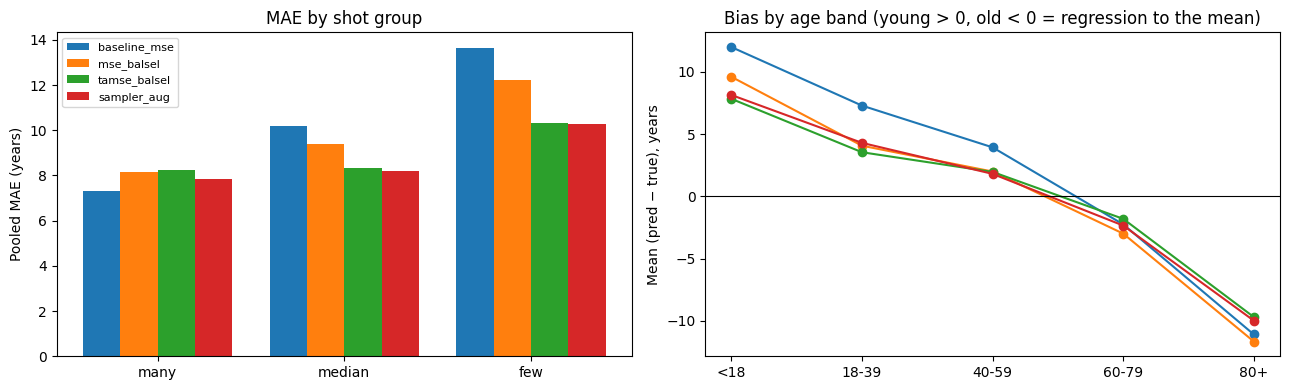

In [43]:
if pp:
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    groups = ["many", "median", "few"]
    w = 0.8 / len(pp)
    for i, (n, p) in enumerate(pp.items()):
        pm = pooled_metrics(p)
        ax[0].bar(np.arange(3) + i * w, [pm[f"MAE_{g}"] for g in groups], w, label=n)
    ax[0].set_xticks(np.arange(3) + 0.4 - w / 2); ax[0].set_xticklabels(groups)
    ax[0].set_ylabel("Pooled MAE (years)"); ax[0].set_title("MAE by shot group"); ax[0].legend(fontsize=8)

    bins = [0, 18, 40, 60, 80, 101]; lab = ["<18", "18-39", "40-59", "60-79", "80+"]
    for n, p in pp.items():
        d = pd.read_csv(p); d = d[d["shots"] == SHOTS]
        band = pd.cut(d["age"], bins=bins, labels=lab, right=False)
        ax[1].plot(lab, (d["pred"] - d["age"]).groupby(band, observed=False).mean().values, marker="o", label=n)
    ax[1].axhline(0, c="k", lw=.8); ax[1].set_ylabel("Mean (pred − true), years")
    ax[1].set_title("Bias by age band (young > 0, old < 0 = regression to the mean)")
    plt.tight_layout(); plt.savefig(OUT / "rare_age_comparison.png", dpi=160); plt.show()

## 14. Final quality checklist and reporting

Before concluding, verify:
- Original ZIP and `ptbxl_database.csv` unchanged; every exclusion documented (`dataset_reports/`).
- Waveforms validated (100 Hz, 12 leads, 1000 samples); no patient overlap across splits (asserted in the training code when `patient_id` exists).
- Normalisation statistics, loss weights, label prior and sampler probabilities come from training folds only.
- All runs used identical folds, epochs, batch size, seed and LR schedule.
- Hyper-parameters (`alpha`, `clip`, `beta`, `noise_sigma`, ...) were chosen on validation data, not test results, and then frozen.
- Report pooled results with CIs, per-group counts, **and the many-shot / overall cost** of any rare-age gain. Repeat with 2–3 seeds for the final claim.
- Disclose: model is a reconstruction; TA-MSE is your proposed placeholder; few/median/many groups are defined by exact-age counts over the whole filtered dataset (paper convention).

**Suggested next experiments** (only if the above is clean): `--variant base`, softer TA-MSE (`--alpha 0.3 --clip 3`), `--sampler balanced --beta 0.3/0.7`, C-Mixup augmentation.

*Research implementation for age estimation; not a clinically validated diagnostic tool.*

In [38]:
pairs = [("baseline_mse", "sampler_aug"), ("baseline_mse", "sampler_aug_msesel")]
for base, prop in pairs:
    print("\n" + "=" * 90 + f"\n{prop}  vs  {base}\n" + "=" * 90)
    run_cmd([sys.executable, CODE_DIR / "analyze_pooled.py",
             "--baseline", pp[base], "--proposed", pp[prop], "--shots", SHOTS],
            log_path=OUT / f"compare_{prop}_vs_{base}.txt")


sampler_aug  vs  baseline_mse
$ "c:\Users\Tankala Bhaskar teja\AppData\Local\Programs\Python\Python313\python.exe" "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\code\analyze_pooled.py" --baseline "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_final_seed43\preds_lite_baseline_mse.csv" --proposed "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_final_seed43\preds_lite_sampler_aug.csv" --shots 10

##### C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_final_seed43\preds_lite_sampler_aug.csv  vs  C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_final_seed43\preds_lite_baseline_mse.csv   (15218 ECGs, shots=10)
 group     n metric  baseline  proposed  diff(prop-base)            95% CI CI excludes 0
   all 15218    MSE     95.17    111.26            16.09    [14.04, 18.04]           yes
   all 15218    MAE      7.54      8.12             0.58      [0.51, 0.66]           yes
   all 15218     GM      4.89      5.23             0.34      [0.25, 0.44]     

In [54]:
pairs = [("baseline_mse", "sampler_aug"), ("baseline_mse", "sampler_aug_msesel")]
for base, prop in pairs:
    print("\n" + "=" * 90 + f"\n{prop}  vs  {base}\n" + "=" * 90)
    run_cmd([sys.executable, CODE_DIR / "analyze_pooled.py",
             "--baseline", pp[base], "--proposed", pp[prop], "--shots", SHOTS],
            log_path=OUT / f"compare_{prop}_vs_{base}.txt")


sampler_aug  vs  baseline_mse
$ "c:\Users\Tankala Bhaskar teja\AppData\Local\Programs\Python\Python313\python.exe" "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\code\analyze_pooled.py" --baseline "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_ep200\preds_lite_baseline_mse.csv" --proposed "C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_ep200\preds_lite_sampler_aug.csv" --shots 10

##### C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_ep200\preds_lite_sampler_aug.csv  vs  C:\Users\Tankala Bhaskar teja\DS_RESEARCH_CLAUDE\runs\v2_ep200\preds_lite_baseline_mse.csv   (21748 ECGs, shots=10)
 group     n metric  baseline  proposed  diff(prop-base)            95% CI CI excludes 0
   all 21748    MSE     92.83    105.24            12.41    [10.65, 14.15]           yes
   all 21748    MAE      7.41      7.84             0.43      [0.37, 0.50]           yes
   all 21748     GM      4.78      4.99             0.21      [0.13, 0.29]           yes
  many 20179    MS